# Lab 04 – Fine-Tuning an LLM Using LoRA / QLoRA

**Module:** PUSL3205 – Large Language Models and Generative AI

**Environment:** Google Colab

**Model:** Qwen/Qwen2.5-0.5B-Instruct

**Domain:** Computer Shop Question-and-Answer Assistant

## 1. Introduction

In this practical, I explore how a pretrained instruction-following language model can be adapted to answer questions about a specific domain.

The selected domain is a fictional computer shop called ByteBridge Computers. The goal is to investigate whether a small collection of domain-specific questions and answers can influence the model's responses.

Instead of updating every parameter in the model, the experiment uses Low-Rank Adaptation (LoRA), a parameter-efficient fine-tuning technique.

The experiment compares the original model and the fine-tuned model on the same questions, including questions whose exact wording does not appear in the training dataset.

## 2. Objectives

- Explore the hardware requirements of LLM fine-tuning.
- Load a small pretrained instruction-tuned model.
- Prepare a question-and-answer dataset containing at least 30 examples.
- Configure LoRA or QLoRA using PEFT.
- Fine-tune the model using supervised learning.
- Monitor training performance.
- Compare original and fine-tuned responses.
- Investigate the limitations of training with a small dataset.
- Save and verify the trained adapter.

In [2]:

%pip install -q -U transformers datasets peft trl accelerate bitsandbytes matplotlib "pandas==2.2.3" "pyarrow==23.0.1"


## 3. Environment and GPU Availability

Before fine-tuning the model, the available hardware is checked.

A GPU is useful because language-model training requires large numbers of matrix operations during forward propagation and backpropagation.

GPU acceleration can substantially reduce training time compared with CPU execution.

The GPU name and total available memory are recorded to determine whether ordinary LoRA or 4-bit QLoRA is suitable.

Project folders are created to keep the dataset, experiment results, model adapter and screenshots organised.

In [3]:
import os
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path("/content/Lab-04-LoRA-Fine-Tuning")

DATA_DIR = ROOT / "dataset"
RESULTS_DIR = ROOT / "results"
MODEL_DIR = ROOT / "saved-adapter"
SCREENSHOT_DIR = ROOT / "screenshots"
NOTEBOOK_DIR = ROOT / "notebooks"

for folder in [
    DATA_DIR,
    RESULTS_DIR,
    MODEL_DIR,
    SCREENSHOT_DIR,
    NOTEBOOK_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("GPU INFORMATION")
print("=" * 55)

GPU_AVAILABLE = torch.cuda.is_available()

print("CUDA available:", GPU_AVAILABLE)

if GPU_AVAILABLE:
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU:", gpu_name)
    print(f"GPU Memory: {gpu_memory:.2f} GB")
else:
    print("No NVIDIA GPU detected.")

print("\nProject folder:", ROOT)

if not GPU_AVAILABLE:
    raise RuntimeError(
        "Select a GPU runtime in Colab before continuing."
    )

GPU INFORMATION
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB

Project folder: /content/Lab-04-LoRA-Fine-Tuning


## 4. Dataset Preparation

For this experiment, I created a small question-and-answer dataset based on a fictional computer shop called ByteBridge Computers.

The dataset contains 40 questions and answers describing the shop's opening hours, delivery policies, payments, warranties, repairs and customer services.

These details are fictional and are used only for demonstrating domain-specific LLM fine-tuning.

The question-and-answer records are saved in JSONL format so they can be inspected and reused.

The main objective is to investigate whether fine-tuning helps the pretrained model answer questions about information that was not part of its original training context.

In [4]:
training_pairs = [
    ("What are the weekday opening hours?",
     "ByteBridge Computers is open Monday to Friday from 9:00 AM to 6:00 PM."),

    ("When is the shop open on Saturday?",
     "On Saturday, ByteBridge Computers is open from 10:00 AM to 4:00 PM."),

    ("Is the shop open on Sundays?",
     "ByteBridge Computers is closed on Sundays."),

    ("Where is the shop located?",
     "The fictional ByteBridge Computers shop is located at Unit 12, Cedar Arcade, Colombo 05."),

    ("What email should customers use?",
     "Customers can email help@bytebridge.example."),

    ("What payment methods are accepted?",
     "The shop accepts cash, Visa, Mastercard, and LankaQR."),

    ("Does the shop accept online orders?",
     "Yes. Customers can place an order by emailing help@bytebridge.example."),

    ("Where does the shop deliver?",
     "ByteBridge Computers delivers within Colombo and nearby suburbs."),

    ("How much is local delivery?",
     "Local delivery costs LKR 450 per order."),

    ("When is delivery free?",
     "Delivery is free for orders worth LKR 25,000 or more."),

    ("How long does local delivery take?",
     "Local delivery normally takes 2 to 3 business days after order confirmation."),

    ("Can customers collect orders?",
     "Yes. Customers can collect confirmed orders at the shop without a pickup fee."),

    ("When can I collect an order?",
     "Pickup orders are usually ready within 24 hours after confirmation."),

    ("How long can an item be reserved?",
     "A requested item can be reserved for 48 hours without a deposit."),

    ("What is the return period?",
     "Unused and unopened items may be returned within 7 calendar days with the receipt."),

    ("Can opened items be returned?",
     "Opened items cannot be returned unless a fault is confirmed."),

    ("What happens if an item is faulty?",
     "Report a faulty item within 7 days so the shop can inspect it and explain the warranty options."),

    ("What is the warranty for keyboards?",
     "Keyboards sold by the shop have a 6-month shop warranty."),

    ("What is the warranty for computer mice?",
     "Computer mice sold by the shop have a 6-month shop warranty."),

    ("What warranty comes with laptops?",
     "Laptops include a 12-month manufacturer warranty unless a specific listing states otherwise."),

    ("What is the warranty for charging cables?",
     "Charging cables have a 30-day shop warranty for manufacturing defects."),

    ("Does the shop diagnose laptops?",
     "Yes. ByteBridge Computers offers laptop diagnostic checks."),

    ("How much is a laptop diagnosis?",
     "A laptop diagnostic check costs LKR 1,500."),

    ("Is the diagnosis fee deducted from repairs?",
     "The LKR 1,500 diagnostic fee is waived when the customer approves the repair at the shop."),

    ("How long do simple repairs take?",
     "Simple laptop repairs usually take 3 to 5 business days after approval."),

    ("Does the shop upgrade laptop RAM?",
     "Yes. The shop offers compatible laptop RAM upgrades."),

    ("Does the shop install SSD storage?",
     "Yes. The shop offers compatible SSD upgrades and installation."),

    ("Can the shop reinstall Windows?",
     "Yes. Windows reinstallation is one of the available laptop services."),

    ("Who is responsible for backing up files?",
     "Customers should back up important files before handing in a device for service."),

    ("Does the shop keep customer files after repairs?",
     "The shop policy is not to retain customer personal files after a completed repair."),

    ("Can the shop build a desktop PC?",
     "Yes. ByteBridge Computers accepts custom desktop PC build requests."),

    ("Does a custom PC consultation cost anything?",
     "A consultation for a custom PC build is free."),

    ("Is there a student discount?",
     "Students with a valid student ID get 5% off eligible accessories."),

    ("Are laptops covered by the student discount?",
     "No. The 5% student discount applies to eligible accessories, not laptops."),

    ("Do you support bulk purchases?",
     "Yes. The shop can prepare a bulk quotation for orders of five or more items."),

    ("Are instalment payments available?",
     "No. ByteBridge Computers does not offer instalment payment plans."),

    ("Can I get a digital invoice?",
     "Yes. A digital invoice can be sent to the customer by email on request."),

    ("Does the shop accept used-item trade-ins?",
     "No. The shop does not currently accept trade-ins."),

    ("How long do special orders take?",
     "Special orders normally take 5 to 10 business days, depending on supplier availability."),

    ("Does the shop price-match competitors?",
     "No. ByteBridge Computers does not offer a price-match guarantee.")
]

assert len(training_pairs) == 40

train_records = [
    {"question": q, "answer": a}
    for q, a in training_pairs
]

with open(
    DATA_DIR / "training_qa.jsonl",
    "w",
    encoding="utf-8"
) as f:
    for item in train_records:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Training pairs:", len(train_records))
display(pd.DataFrame(train_records).head(8))

Training pairs: 40


,question,answer
0,What are the weekday opening hours?,ByteBridge Computers is open Monday to Friday ...
1,When is the shop open on Saturday?,"On Saturday, ByteBridge Computers is open from..."
2,Is the shop open on Sundays?,ByteBridge Computers is closed on Sundays.
3,Where is the shop located?,The fictional ByteBridge Computers shop is loc...
4,What email should customers use?,Customers can email help@bytebridge.example.
5,What payment methods are accepted?,"The shop accepts cash, Visa, Mastercard, and L..."
6,Does the shop accept online orders?,Yes. Customers can place an order by emailing ...
7,Where does the shop deliver?,ByteBridge Computers delivers within Colombo a...


In [7]:
# Hugging Face Transformers
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

# Hugging Face Datasets
from datasets import Dataset

# PEFT - LoRA and adapter loading
from peft import (
    LoraConfig,
    PeftModel
)

# TRL - Supervised fine-tuning
from trl import (
    SFTConfig,
    SFTTrainer
)

print("All required LLM libraries imported successfully!")

All required LLM libraries imported successfully!


In [8]:
GPU_NAME = torch.cuda.get_device_name(0)

GPU_GB = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("GPU:", GPU_NAME)
print(f"GPU Memory: {GPU_GB:.2f} GB")

GPU: Tesla T4
GPU Memory: 14.56 GB


In [9]:
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

USE_QLORA = True

COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

quant_config = (
    BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE
    )
    if USE_QLORA
    else None
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Model:", MODEL_ID)
print("Method:", "QLoRA" if USE_QLORA else "LoRA")
print("Compute dtype:", COMPUTE_DTYPE)
print("Tokenizer vocabulary:", len(tokenizer))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Model: Qwen/Qwen2.5-0.5B-Instruct
Method: QLoRA
Compute dtype: torch.bfloat16
Tokenizer vocabulary: 151665


## 5. Validation and Testing Data

Separate validation and testing questions are prepared to assess the model beyond the exact wording of the training examples.

Four validation questions are used to monitor training performance.

Ten additional questions are reserved for comparing the original and fine-tuned models.

The test set includes paraphrased questions about facts present in the training data, as well as questions whose answers were not provided in the dataset.

This helps evaluate whether the fine-tuned model can respond to differently worded questions and whether it avoids inventing unsupported information.

In [5]:
validation_pairs = [
    (
        "What time do you start business on weekdays?",
        "ByteBridge Computers is open Monday to Friday from 9:00 AM to 6:00 PM."
    ),
    (
        "What is the normal delivery charge around Colombo?",
        "Local delivery costs LKR 450 per order."
    ),
    (
        "Do you fit extra memory in notebooks?",
        "Yes. The shop offers compatible laptop RAM upgrades."
    ),
    (
        "Is there a guarantee on keyboards?",
        "Keyboards sold by the shop have a 6-month shop warranty."
    )
]

test_cases = [
    (
        "Can I visit the store on a Sunday?",
        "ByteBridge Computers is closed on Sundays.",
        "Known policy"
    ),
    (
        "At what value does shipping become free?",
        "Delivery is free for orders worth LKR 25,000 or more.",
        "Known policy"
    ),
    (
        "How soon can I pick up an order after it is confirmed?",
        "Pickup orders are usually ready within 24 hours after confirmation.",
        "Known policy"
    ),
    (
        "What if I change my mind after opening a purchase?",
        "Opened items cannot be returned unless a fault is confirmed.",
        "Known policy"
    ),
    (
        "Do you charge students less for a laptop?",
        "No. The 5% student discount applies to eligible accessories, not laptops.",
        "Known policy"
    ),
    (
        "Could I pay for a PC in monthly instalments?",
        "No. ByteBridge Computers does not offer instalment payment plans.",
        "Known policy"
    ),
    (
        "How much will a diagnostic check cost?",
        "A laptop diagnostic check costs LKR 1,500.",
        "Known policy"
    ),
    (
        "Do you buy my old laptop when I upgrade?",
        "No. The shop does not currently accept trade-ins.",
        "Known policy"
    ),
    (
        "What is the store manager's personal phone number?",
        "Not specified in the training dataset.",
        "Unknown fact"
    ),
    (
        "What exact laptop models are in stock today?",
        "Not specified in the training dataset.",
        "Unknown fact"
    )
]

train_questions = {
    question.strip().lower()
    for question, answer in training_pairs
}

assert all(
    question.strip().lower() not in train_questions
    for question, answer in validation_pairs
)

assert all(
    question.strip().lower() not in train_questions
    for question, reference, kind in test_cases
)

with open(
    DATA_DIR / "validation_qa.jsonl",
    "w",
    encoding="utf-8"
) as f:
    for question, answer in validation_pairs:
        f.write(
            json.dumps({
                "question": question,
                "answer": answer
            }) + "\n"
        )

with open(
    DATA_DIR / "unseen_test_questions.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        [
            {
                "question": question,
                "reference": reference,
                "type": kind
            }
            for question, reference, kind in test_cases
        ],
        f,
        indent=2
    )

print("Training questions:", len(training_pairs))
print("Validation questions:", len(validation_pairs))
print("Unseen test questions:", len(test_cases))

display(
    pd.DataFrame(
        test_cases,
        columns=["Question", "Reference Answer", "Type"]
    )
)

Training questions: 40
Validation questions: 4
Unseen test questions: 10


,Question,Reference Answer,Type
0,Can I visit the store on a Sunday?,ByteBridge Computers is closed on Sundays.,Known policy
1,At what value does shipping become free?,"Delivery is free for orders worth LKR 25,000 o...",Known policy
2,How soon can I pick up an order after it is co...,Pickup orders are usually ready within 24 hour...,Known policy
3,What if I change my mind after opening a purch...,Opened items cannot be returned unless a fault...,Known policy
4,Do you charge students less for a laptop?,No. The 5% student discount applies to eligibl...,Known policy
5,Could I pay for a PC in monthly instalments?,No. ByteBridge Computers does not offer instal...,Known policy
6,How much will a diagnostic check cost?,"A laptop diagnostic check costs LKR 1,500.",Known policy
7,Do you buy my old laptop when I upgrade?,No. The shop does not currently accept trade-ins.,Known policy
8,What is the store manager's personal phone num...,Not specified in the training dataset.,Unknown fact
9,What exact laptop models are in stock today?,Not specified in the training dataset.,Unknown fact


## 6. Selecting the Pretrained Language Model

The pretrained model selected for this experiment is Qwen2.5-0.5B-Instruct.

This is a relatively small instruction-tuned causal language model, making it a suitable candidate for experimenting with parameter-efficient fine-tuning.

The experiment uses the Hugging Face Transformers library to load the model and its tokenizer.

Four-bit quantisation can be enabled to reduce memory requirements. When combined with LoRA, this approach is known as QLoRA.

The same quantisation settings will be applied to the original and fine-tuned models to support a fairer comparison.

In [10]:
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

USE_QLORA = True

COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

quant_config = (
    BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE
    )
    if USE_QLORA
    else None
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

SYSTEM_PROMPT = (
    "You are the information assistant for the fictional "
    "ByteBridge Computers shop. "
    "Use only information you know about its policies. "
    "Answer briefly and accurately. "
    "If a detail is unknown, say it is not available "
    "rather than inventing it."
)

def load_base_model():

    options = {
        "dtype": COMPUTE_DTYPE,
        "device_map": {"": 0}
    }

    if quant_config is not None:
        options["quantization_config"] = quant_config

    return AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        **options
    )

print("Base model:", MODEL_ID)

print(
    "Method:",
    "4-bit QLoRA" if USE_QLORA else "LoRA"
)

print("Compute dtype:", COMPUTE_DTYPE)
print("Tokenizer vocabulary:", len(tokenizer))

Base model: Qwen/Qwen2.5-0.5B-Instruct
Method: 4-bit QLoRA
Compute dtype: torch.bfloat16
Tokenizer vocabulary: 151665


## 7. Original Model Evaluation

Before fine-tuning, the pretrained model is tested using the reserved evaluation questions.

The original responses are saved so they can be compared with the fine-tuned model's responses.

The same system prompt, questions and deterministic generation settings are used in both evaluations.

Since the computer shop is fictional, the pretrained model may not know its policies. An answer that admits missing information can be more appropriate than an invented factual claim.

In [12]:
import json
import gc
import torch

@torch.inference_mode()
def answer_question(network, question, max_new_tokens=85):

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": question
        }
    ]

    # Correct handling for newer Transformers versions
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    # Move actual tensors to the model's device
    model_device = next(network.parameters()).device

    inputs = {
        key: value.to(model_device)
        for key, value in inputs.items()
        if key in ("input_ids", "attention_mask")
    }

    network.eval()

    # Pass input_ids and attention_mask correctly
    generated = network.generate(
        **inputs,
        do_sample=False,
        max_new_tokens=max_new_tokens,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

    # Extract only newly generated tokens
    input_length = inputs["input_ids"].shape[-1]

    output_tokens = generated[0, input_length:]

    response = tokenizer.decode(
        output_tokens,
        skip_special_tokens=True
    )

    return response.strip()


# Reuse the model already downloaded if it exists
if "baseline_model" not in globals():
    baseline_model = load_base_model()

baseline_responses = []

print("ORIGINAL MODEL EVALUATION")
print("=" * 60)

for i, (question, reference, kind) in enumerate(
    test_cases, start=1
):

    response = answer_question(
        baseline_model,
        question
    )

    baseline_responses.append(response)

    print(f"\nQuestion {i}: {question}")
    print("Original response:", response)


# Save baseline results
with open(
    RESULTS_DIR / "original-model-answers.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        [
            {
                "question": question,
                "answer": response
            }
            for (question, reference, kind), response
            in zip(test_cases, baseline_responses)
        ],
        f,
        indent=2
    )

# Release model memory before fine-tuning
del baseline_model

gc.collect()
torch.cuda.empty_cache()

print("\nOriginal model responses saved successfully!")
print("GPU memory released for fine-tuning.")

ORIGINAL MODEL EVALUATION

Question 1: Can I visit the store on a Sunday?
Original response: Yes, you can visit the store on a Sunday as long as there are no other customers in the store at that time.

Question 2: At what value does shipping become free?
Original response: Shipping becomes free when the goods reach your designated destination without any additional charges. This typically occurs at ports of entry or upon arrival in your country's customs territory.

Question 3: How soon can I pick up an order after it is confirmed?
Original response: Orders are typically shipped within 1-2 business days from the date of confirmation. However, shipping times may vary based on your location and the specific order details.

Question 4: What if I change my mind after opening a purchase?
Original response: If you change your mind after purchasing from ByteBridge Computers, you can proceed with the transaction as usual until the item arrives or until you receive an apology from ByteBridge Co

## 8. LoRA Configuration

Low-Rank Adaptation (LoRA) is configured using the PEFT library.

Instead of updating the entire pretrained model, LoRA introduces smaller trainable matrices into selected neural network layers.

The experiment uses a rank of 16, an alpha value of 32 and dropout of 0.05.

The attention projection layers are selected as LoRA target modules.

This approach reduces the number of parameters that require updates during fine-tuning.

In [13]:
def prompt_completion(question, answer):

    return {
        "prompt": [
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": question
            }
        ],
        "completion": [
            {
                "role": "assistant",
                "content": answer
            }
        ]
    }


train_ds = Dataset.from_list([
    prompt_completion(question, answer)
    for question, answer in training_pairs
])

val_ds = Dataset.from_list([
    prompt_completion(question, answer)
    for question, answer in validation_pairs
])

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ]
)

print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))

print("\nLoRA Configuration:")
print(lora_config)

display(train_ds[0])

Training examples: 40
Validation examples: 4

LoRA Configuration:
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.22.0', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'q_proj', 'o_proj', 'v_proj', 'k_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, astra_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow

{'prompt': [{'content': 'You are the information assistant for the fictional ByteBridge Computers shop. Use only information you know about its policies. Answer briefly and accurately. If a detail is unknown, say it is not available rather than inventing it.',
   'role': 'system'},
  {'content': 'What are the weekday opening hours?', 'role': 'user'}],
 'completion': [{'content': 'ByteBridge Computers is open Monday to Friday from 9:00 AM to 6:00 PM.',
   'role': 'assistant'}]}

## 9. Supervised Fine-Tuning

The selected Qwen2.5-0.5B-Instruct model is fine-tuned using Hugging Face TRL's `SFTTrainer`.

The training dataset contains 40 question-and-answer pairs about a fictional computer shop, while four separate questions are used for validation.

I configured the model using 4-bit QLoRA so that fine-tuning could be performed with lower GPU memory requirements. Instead of updating the entire pretrained model, only the LoRA adapter parameters are trained.

### 9.1 Training Configuration

The following settings are used:

- **Base model:** Qwen/Qwen2.5-0.5B-Instruct
- **GPU:** NVIDIA Tesla T4
- **Fine-tuning method:** 4-bit QLoRA
- **Training examples:** 40
- **Validation examples:** 4
- **Learning rate:** 0.0002
- **Training epochs:** 10
- **Batch size:** 2
- **Gradient accumulation steps:** 2
- **LoRA rank:** 16
- **LoRA alpha:** 32
- **Loss function:** Negative Log-Likelihood (NLL)

### 9.2 GPU Compatibility Adjustments

During implementation, I encountered compatibility issues involving the precision used for GPU operations.

The Tesla T4 has CUDA compute capability 7.5, so FP16 was selected for the training computations.

The initial training attempt encountered an error involving BF16 operations. The training configuration was updated to use standard NLL loss.

A further error occurred because the gradient scaler encountered BF16 gradients. To address this, the trainable LoRA adapter parameters were converted to FP32 while retaining 4-bit quantisation for the base model.

These adjustments were intended to allow parameter-efficient fine-tuning to run on the available GPU without loading the entire model in full precision.

### 9.3 Training and Validation

During training, the model predicts the expected answers from the supplied questions.

The optimiser updates the trainable adapter parameters using backpropagation.

Training loss is recorded throughout the experiment, while validation loss is calculated using questions kept separate from the training dataset.

After training, the recorded losses will be analysed to determine how the model's performance changed over the ten epochs.

The fine-tuned model will also be tested against the original model using the same unseen questions.

In [17]:
import torch
import pandas as pd
from collections import Counter
from IPython.display import display

# Check the current trainable parameter types
print("BEFORE FIX")
print("=" * 60)

before = Counter(
    str(param.dtype)
    for param in trainer.model.parameters()
    if param.requires_grad
)

print("Trainable parameter dtypes:", dict(before))

# MAIN FIX:
# Convert only trainable LoRA parameters to float32
fixed_count = 0

for name, param in trainer.model.named_parameters():

    if param.requires_grad:

        if param.dtype != torch.float32:
            param.data = param.data.to(torch.float32)
            fixed_count += 1

        # Clear gradients left by the failed attempt
        param.grad = None

print("\nAFTER FIX")
print("=" * 60)

after = Counter(
    str(param.dtype)
    for param in trainer.model.parameters()
    if param.requires_grad
)

print("Trainable parameter dtypes:", dict(after))
print("Parameters converted:", fixed_count)

# Check that no trainable BF16 parameters remain
assert all(
    param.dtype == torch.float32
    for param in trainer.model.parameters()
    if param.requires_grad
), "Some trainable parameters are still not float32."

# Recreate the optimizer on the next training attempt
trainer.optimizer = None
trainer.lr_scheduler = None

print("\nLoRA precision fixed successfully!")
print("The 4-bit base model remains unchanged.")

BEFORE FIX
Trainable parameter dtypes: {'torch.bfloat16': 192}

AFTER FIX
Trainable parameter dtypes: {'torch.float32': 192}
Parameters converted: 192

LoRA precision fixed successfully!
The 4-bit base model remains unchanged.


In [18]:
print("STARTING FIXED QLORA TRAINING")
print("=" * 60)

print("GPU:", torch.cuda.get_device_name(0))
print("Training FP16 enabled:", trainer.args.fp16)
print("Training BF16 enabled:", trainer.args.bf16)
print("Loss type:", trainer.args.loss_type)

# Train the model
train_output = trainer.train()

print("\nFine-tuning completed successfully!")

print(
    "Final reported training loss:",
    train_output.training_loss
)

# Save training history
log_df = pd.DataFrame(
    trainer.state.log_history
)

log_df.to_csv(
    RESULTS_DIR / "training-history.csv",
    index=False
)

print("\nFINAL TRAINING HISTORY")
display(log_df.tail(12))

STARTING FIXED QLORA TRAINING
GPU: Tesla T4
Training FP16 enabled: True
Training BF16 enabled: False
Loss type: nll


Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,1.948263,1.950048,2.040275,0.583333,3543.000000
2,1.432593,1.594328,1.413357,0.644689,6769.000000
3,1.469365,1.350451,1.426636,0.662546,9995.000000
4,0.748163,1.077467,1.112620,0.741758,13221.000000
5,0.692031,1.106533,1.030536,0.728938,16447.000000
6,0.394508,1.048825,0.911303,0.693223,19673.000000
7,0.315258,1.022129,0.828048,0.775183,22899.000000
8,0.121898,1.029030,0.761914,0.798077,26125.000000
9,0.097853,1.031202,0.708530,0.793040,29351.000000
10,0.055543,1.038247,0.709384,0.793040,32577.000000



Fine-tuning completed successfully!
Final reported training loss: 0.7887049389630556

FINAL TRAINING HISTORY


,loss,grad_norm,learning_rate,entropy,mean_token_accuracy,num_tokens,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_mean_token_accuracy,eval_num_tokens,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
49,0.060426,2.210660,0.000036,0.239340,0.992647,27413.0,8.4,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50,0.157386,4.434219,0.000032,0.393285,0.973897,28059.0,8.6,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51,0.075977,2.312073,0.000027,0.295421,1.000000,28717.0,8.8,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
52,0.097853,4.192698,0.000023,0.297915,0.986111,29351.0,9.0,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
53,NaN,NaN,NaN,NaN,NaN,NaN,9.0,90,1.031202,0.2187,18.293,9.146,0.708530,0.79304,29351.0,NaN,NaN,NaN,NaN,NaN
54,0.100362,3.242286,0.000019,0.288481,0.986842,30008.0,9.2,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
55,0.048673,3.595115,0.000015,0.214977,0.992424,30636.0,9.4,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,0.101904,4.798879,0.000011,0.295839,0.983602,31293.0,9.6,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
57,0.070533,2.332356,0.000006,0.279763,0.984848,31930.0,9.8,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,0.055543,1.489894,0.000002,0.236516,1.000000,32577.0,10.0,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Training Performance Analysis

The recorded training history is analysed to understand how the model's loss changes during fine-tuning.

Training loss measures the error associated with predicting the target answers.

Validation loss is calculated using separate question-and-answer examples.

Both losses are plotted to investigate the training behaviour.

A decrease in loss may indicate that the model is learning patterns from the provided examples. However, lower loss alone does not guarantee that generated answers are factually correct or that the model generalises to new questions.

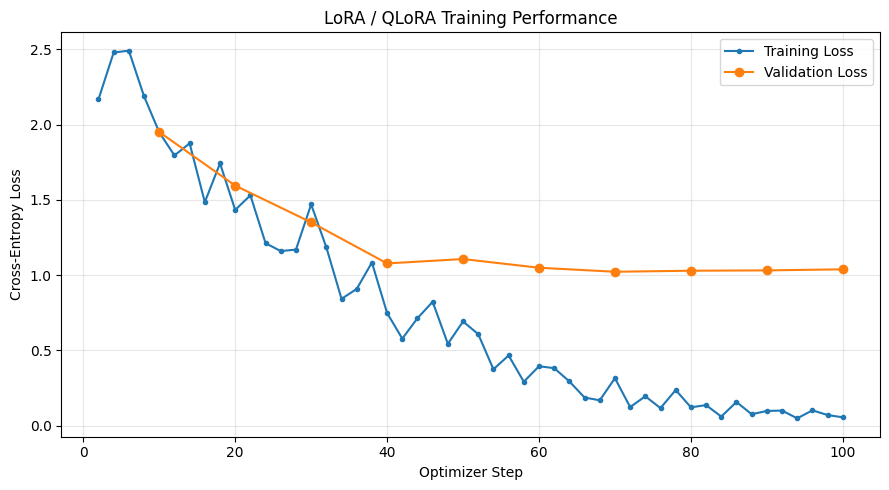

In [19]:
log_df = pd.read_csv(
    RESULTS_DIR / "training-history.csv"
)

training_logs = log_df.dropna(
    subset=["loss"]
) if "loss" in log_df else pd.DataFrame()

validation_logs = log_df.dropna(
    subset=["eval_loss"]
) if "eval_loss" in log_df else pd.DataFrame()

plt.figure(figsize=(9, 5))

if len(training_logs):
    plt.plot(
        training_logs["step"],
        training_logs["loss"],
        marker=".",
        label="Training Loss"
    )

if len(validation_logs):
    plt.plot(
        validation_logs["step"],
        validation_logs["eval_loss"],
        marker="o",
        label="Validation Loss"
    )

plt.title("LoRA / QLoRA Training Performance")
plt.xlabel("Optimizer Step")
plt.ylabel("Cross-Entropy Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "training-loss.png",
    dpi=220
)

plt.show()

## 11. Comparing the Original and Fine-Tuned Models

The fine-tuned model is evaluated using exactly the same ten questions that were previously given to the original model.

The comparison includes questions that do not appear verbatim in the training dataset.

Both models use identical generation settings to reduce differences caused by sampling.

The generated responses are recorded alongside the expected answers.

The results are examined to identify correct answers, improvements, incorrect responses and unsupported claims.

This comparison provides practical evidence of how the LoRA fine-tuning process affected the model's behaviour.

In [20]:
tuned_model = trainer.model

tuned_model.config.use_cache = True

tuned_responses = []

for i, (question, reference, kind) in enumerate(
    test_cases, start=1
):

    tuned_answer = answer_question(
        tuned_model,
        question
    )

    tuned_responses.append(tuned_answer)

    print("\n" + "=" * 65)
    print(f"QUESTION {i}: {question}")

    print("\nORIGINAL MODEL:")
    print(baseline_responses[i - 1])

    print("\nFINE-TUNED MODEL:")
    print(tuned_answer)

    print("\nREFERENCE ANSWER:")
    print(reference)


comparison_df = pd.DataFrame([
    {
        "Question": question,

        "Question type": kind,

        "Reference answer": reference,

        "Original model": original,

        "Fine-tuned model": tuned,

        "Original accuracy (manual)": "",

        "Fine-tuned accuracy (manual)": "",

        "Notes": ""
    }

    for (question, reference, kind), original, tuned
    in zip(
        test_cases,
        baseline_responses,
        tuned_responses
    )
])

comparison_df.to_csv(
    RESULTS_DIR / "original-vs-finetuned.csv",
    index=False
)

display(
    comparison_df[
        [
            "Question",
            "Original model",
            "Fine-tuned model",
            "Reference answer"
        ]
    ]
)


QUESTION 1: Can I visit the store on a Sunday?

ORIGINAL MODEL:
Yes, you can visit the store on a Sunday as long as there are no other customers in the store at that time.

FINE-TUNED MODEL:
Yes. The shop is closed on Sundays.

REFERENCE ANSWER:
ByteBridge Computers is closed on Sundays.

QUESTION 2: At what value does shipping become free?

ORIGINAL MODEL:
Shipping becomes free when the goods reach your designated destination without any additional charges. This typically occurs at ports of entry or upon arrival in your country's customs territory.

FINE-TUNED MODEL:
Shipping becomes free for orders worth LKR 25,000 or more.

REFERENCE ANSWER:
Delivery is free for orders worth LKR 25,000 or more.

QUESTION 3: How soon can I pick up an order after it is confirmed?

ORIGINAL MODEL:
Orders are typically shipped within 1-2 business days from the date of confirmation. However, shipping times may vary based on your location and the specific order details.

FINE-TUNED MODEL:
Confirm a order

,Question,Original model,Fine-tuned model,Reference answer
0,Can I visit the store on a Sunday?,"Yes, you can visit the store on a Sunday as lo...",Yes. The shop is closed on Sundays.,ByteBridge Computers is closed on Sundays.
1,At what value does shipping become free?,Shipping becomes free when the goods reach you...,"Shipping becomes free for orders worth LKR 25,...","Delivery is free for orders worth LKR 25,000 o..."
2,How soon can I pick up an order after it is co...,Orders are typically shipped within 1-2 busine...,Confirm a order no more than 48 hours ahead of...,Pickup orders are usually ready within 24 hour...
3,What if I change my mind after opening a purch...,If you change your mind after purchasing from ...,If a customer changes their mind before submit...,Opened items cannot be returned unless a fault...
4,Do you charge students less for a laptop?,"No, we do not charge students less for laptops...",No. Laptops are not normally offered for sale ...,No. The 5% student discount applies to eligibl...
5,Could I pay for a PC in monthly instalments?,"Yes, you could pay for a PC in monthly instalm...",Yes. The shop offers monthly payment plans wit...,No. ByteBridge Computers does not offer instal...
6,How much will a diagnostic check cost?,A diagnostic check costs between $50 to $200 d...,"A diagnostic check costs LKR 1,500.","A laptop diagnostic check costs LKR 1,500."
7,Do you buy my old laptop when I upgrade?,"Yes, we do purchase your old laptop when upgra...",Yes. The shop accepts pre-owned accessories af...,No. The shop does not currently accept trade-ins.
8,What is the store manager's personal phone num...,The store manager's personal phone number is n...,The fictional ByteBridge Computers shop has no...,Not specified in the training dataset.
9,What exact laptop models are in stock today?,Laptops are currently in stock for the followi...,Laptops AC/DC 16GB RAM 450W 5.5L.,Not specified in the training dataset.


## 12. Observations and Response Evaluation

The original and fine-tuned responses are compared against the reference answers.

Each response should be evaluated for factual correctness, relevance and whether it contains information not supported by the dataset.

Responses can be categorised as correct, partly correct or incorrect/unsupported.

The evaluation also considers cases where the model appropriately acknowledges that information is unavailable.

This analysis is important because a lower training loss does not necessarily mean every generated response has improved.

The final observations will be written after reviewing the actual model outputs.

In [21]:
print("TEST SET BREAKDOWN")
print("=" * 55)

print(
    comparison_df["Question type"]
    .value_counts()
    .to_string()
)

print("\nMANUAL RESPONSE EVALUATION")
print("=" * 55)

print("1. Open original-vs-finetuned.csv.")
print("2. Compare each response with the reference answer.")

print(
    "3. Mark each answer as Correct, "
    "Partly correct or Incorrect / Unsupported."
)

print(
    "4. Record examples where fine-tuning improved "
    "or worsened the answer."
)

print(
    "5. Include these observations in the final README."
)

TEST SET BREAKDOWN
Question type
Known policy    8
Unknown fact    2

MANUAL RESPONSE EVALUATION
1. Open original-vs-finetuned.csv.
2. Compare each response with the reference answer.
3. Mark each answer as Correct, Partly correct or Incorrect / Unsupported.
4. Record examples where fine-tuning improved or worsened the answer.
5. Include these observations in the final README.


## 13. Saving the Fine-Tuned Model

The trained LoRA adapter is saved separately from the pretrained base model.

This avoids storing a complete duplicate of the original language model.

The adapter parameters, configuration and tokenizer are preserved so the fine-tuned model can be reconstructed later.

Experiment metadata is also saved, including the model identifier, fine-tuning method, dataset size, GPU details and training settings.

Finally, the adapter is reloaded onto the original pretrained model to verify that the saved files can be used for future inference.

In [22]:
tuned_model.save_pretrained(
    MODEL_DIR,
    safe_serialization=True
)

tokenizer.save_pretrained(MODEL_DIR)

metadata = {
    "base_model": MODEL_ID,

    "method": (
        "QLoRA 4-bit"
        if USE_QLORA
        else "LoRA"
    ),

    "gpu_name": GPU_NAME,
    "gpu_memory_gib": round(GPU_GB, 2),

    "train_pairs": len(training_pairs),
    "validation_pairs": len(validation_pairs),

    "unseen_test_questions": len(test_cases),

    "learning_rate": training_args.learning_rate,

    "epochs": training_args.num_train_epochs,

    "lora_r": lora_config.r,
    "lora_alpha": lora_config.lora_alpha,

    "seed": SEED,

    "training_loss": float(
        train_output.training_loss
    ),

    "training_runtime_seconds": float(
        train_output.metrics.get(
            "train_runtime", 0
        )
    ),

    "note": (
        "Fictional shop. Response correctness "
        "requires manual evaluation."
    )
}

with open(
    RESULTS_DIR / "experiment-summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("SAVED ADAPTER FILES")
print("=" * 55)

for file in sorted(MODEL_DIR.iterdir()):
    print(file.name)

# Release training resources
del trainer
del tuned_model
del train_model

gc.collect()
torch.cuda.empty_cache()

# Reload the base model and adapter
reloaded_base = load_base_model()

reloaded_model = PeftModel.from_pretrained(
    reloaded_base,
    str(MODEL_DIR)
)

print("\nRELOADED MODEL SAMPLE:")

print(
    answer_question(
        reloaded_model,
        test_cases[0][0]
    )
)

print("\nAdapter reloaded successfully.")

SAVED ADAPTER FILES
README.md
adapter_config.json
adapter_model.safetensors
chat_template.jinja
tokenizer.json
tokenizer_config.json


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


RELOADED MODEL SAMPLE:
Yes. The shop is closed on Sundays.

Adapter reloaded successfully.
